# 02 · Modelos de sentimiento (desarrollo exploratorio)

> **Importante:** este notebook conserva el desarrollo inicial y no es la fuente de las cifras finales. El protocolo oficial 64/16/20, la eliminación de títulos automáticos de estrellas y la selección por validación están en `src/train.py`. Ejecutar desde la raíz: `python -m src.train`.

Entrada: `data/electronics_50k.parquet` (del notebook 01). Clases: negativo / neutro / positivo.

Modelos que se comparan:
| # | Modelo | Rol |
|---|---|---|
| 0 | Dummy (clase más frecuente) | piso mínimo |
| 1 | TF-IDF + Regresión logística | modelo lineal manual |
| 2 | TF-IDF + SVM lineal | comparativo |
| 3 | TF-IDF + LightGBM | comparativo (árboles con boosting) |

Métrica principal: **F1 macro** (pesa igual las 3 clases).

In [1]:
!pip -q install scikit-learn lightgbm pandas pyarrow matplotlib seaborn joblib

In [2]:
import re, time, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay, accuracy_score
from lightgbm import LGBMClassifier
SEED = 42

In [3]:
import os, glob
RUTA = "data/electronics_50k.parquet"
if not os.path.exists(RUTA):
    try:                                   # en Colab: sube el parquet generado por el notebook 01
        from google.colab import files
        os.makedirs("data", exist_ok=True)
        up = files.upload()
        os.replace(list(up)[0], RUTA)
    except ImportError:
        RUTA = "../data/electronics_50k.parquet"   # ejecución local desde notebooks/
df = pd.read_parquet(RUTA)
df["label"] = df["label"].astype(str)
print(df.shape); df["label"].value_counts()

(49998, 8)


label
positivo    16666
negativo    16666
neutro      16666
Name: count, dtype: int64

## Preprocesamiento
Minúsculas, quitar URLs/números y **conservar las negaciones** (*not, no, never, n't*): en sentimiento, "not good" ≠ "good".
No se quitan stopwords a mano: TF-IDF con bigramas ya captura "not worth", "stopped working", etc.

In [4]:
NEG = re.compile(r"n't\b")
def limpiar(t):
    t = t.lower()
    t = re.sub(r"https?://\S+", " ", t)
    t = NEG.sub(" not", t)                 # don't → do not
    t = re.sub(r"[^a-z\s!?']", " ", t)    # deja ! y ? (aportan intensidad)
    return re.sub(r"\s+", " ", t).strip()
df["clean"] = df["review"].map(limpiar)
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2, stratify=df["label"], random_state=SEED)
len(X_train), len(X_test)

(39998, 10000)

## Entrenamiento y comparación

In [5]:
tfidf = lambda mf=100_000: TfidfVectorizer(ngram_range=(1,2), min_df=3, max_df=0.9, max_features=mf, sublinear_tf=True)
modelos = {
    "Dummy":            Pipeline([("tfidf", tfidf(1000)), ("clf", DummyClassifier(strategy="most_frequent"))]),
    "TF-IDF + LogReg":  Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(C=2, max_iter=2000))]),
    "TF-IDF + SVM":     Pipeline([("tfidf", tfidf()), ("clf", LinearSVC(C=0.5))]),
    "TF-IDF + LightGBM":Pipeline([("tfidf", tfidf(20_000)), ("clf", LGBMClassifier(n_estimators=400, learning_rate=0.1, num_leaves=63, random_state=SEED, verbose=-1))]),
}
filas, preds = [], {}
for nombre, m in modelos.items():
    t0 = time.time(); m.fit(X_train, y_train); p = m.predict(X_test); preds[nombre] = p
    filas.append({"modelo": nombre, "accuracy": accuracy_score(y_test, p),
                  "f1_macro": f1_score(y_test, p, average="macro"),
                  "f1_neutro": f1_score(y_test, p, labels=["neutro"], average="macro"),
                  "seg": round(time.time()-t0, 1)})
    print(f"{nombre:20s} F1 macro = {filas[-1]['f1_macro']:.3f}")
res = pd.DataFrame(filas).sort_values("f1_macro", ascending=False); res

Dummy                F1 macro = 0.167


TF-IDF + LogReg      F1 macro = 0.765


TF-IDF + SVM         F1 macro = 0.755


TF-IDF + LightGBM    F1 macro = 0.750


,modelo,accuracy,f1_macro,f1_neutro,seg
1,TF-IDF + LogReg,0.7646,0.764639,0.672790,22.9
2,TF-IDF + SVM,0.7563,0.755381,0.658076,7.0
3,TF-IDF + LightGBM,0.7495,0.749996,0.657428,419.3
0,Dummy,0.3333,0.166654,0.000000,5.9


## Ajuste del mejor lineal (C) con validación cruzada

In [6]:
grid = GridSearchCV(modelos["TF-IDF + LogReg"], {"clf__C": [0.5, 1, 2, 4, 8]},
                    scoring="f1_macro", cv=3, n_jobs=-1)
grid.fit(X_train, y_train)
print("Mejor C:", grid.best_params_, "F1 CV:", round(grid.best_score_, 3))
mejor = grid.best_estimator_
p = mejor.predict(X_test)
print(classification_report(y_test, p, digits=3))

Mejor C: {'clf__C': 1} F1 CV: 0.76


              precision    recall  f1-score   support

    negativo      0.760     0.772     0.766      3333
      neutro      0.677     0.677     0.677      3333
    positivo      0.861     0.847     0.854      3334

    accuracy                          0.765     10000
   macro avg      0.766     0.765     0.766     10000
weighted avg      0.766     0.765     0.766     10000



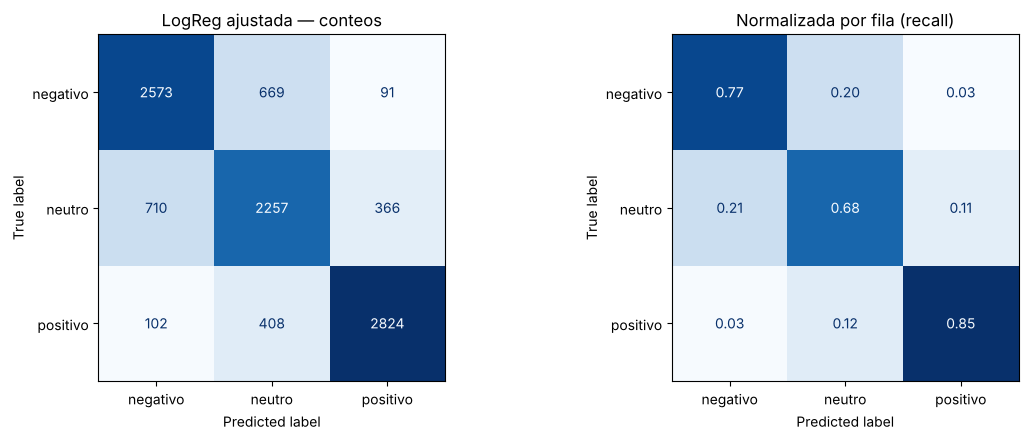

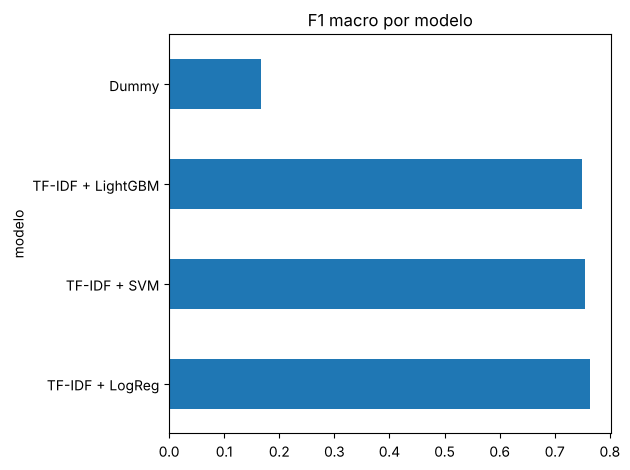

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, p, ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("LogReg ajustada — conteos")
ConfusionMatrixDisplay.from_predictions(y_test, p, ax=ax[1], cmap="Blues", normalize="true", values_format=".2f", colorbar=False)
ax[1].set_title("Normalizada por fila (recall)")
plt.tight_layout(); plt.savefig("data/confusion.png", dpi=120); plt.show()
res.plot.barh(x="modelo", y="f1_macro", legend=False, title="F1 macro por modelo"); plt.tight_layout(); plt.savefig("data/comparacion.png", dpi=120)

## Interpretabilidad: palabras que más empujan a cada clase

In [8]:
vec, clf = mejor.named_steps["tfidf"], mejor.named_steps["clf"]
nombres = np.array(vec.get_feature_names_out())
for i, c in enumerate(clf.classes_):
    top = np.argsort(clf.coef_[i])[-15:][::-1]
    print(f"{c.upper():9s}", ", ".join(nombres[top]))

NEGATIVO  two stars, not, one star, useless, junk, terrible, garbage, poor, return, returned, horrible, returning, not buy, not good, not worth
NEUTRO    three stars, but, ok, three, okay, however, not, otherwise, meh, decent, not bad, works but, stars, not very, though
POSITIVO  great, perfect, love, excellent, five stars, awesome, good, four stars, perfectly, five, works, easy, nice, amazing, highly


## Análisis de errores (para la defensa)

In [9]:
err = pd.DataFrame({"texto": X_test.values, "real": y_test.values, "pred": p})
err = err[err.real != err.pred]
print(err.groupby(["real","pred"]).size().sort_values(ascending=False))
for _, r in err.sample(min(8, len(err)), random_state=1).iterrows():
    print(f"\n[{r.real} → {r.pred}] {r.texto[:220]}")

real      pred    
neutro    negativo    710
negativo  neutro      669
positivo  neutro      408
neutro    positivo    366
positivo  negativo    102
negativo  positivo     91
dtype: int64

[neutro → negativo] gui and sound quality are all excellent if i were using this unit primarily with the form factor gui and sound quality are all excellent if i were using this unit primarily with cd's or usb as the source then i would hav

[neutro → negativo] volume control ?? takes longer to pair there is no volume control once its paired i hear buzzing noice for atleast minutes thats very enoing

[negativo → positivo] problems with macbook incoming sound was a ten my clients kept on complaining about my audio on the other end not sure why this was an issue as i really wanted to keep it super comfortable and great sound

[positivo → neutro] nice sound but not as adjustable as i would nice sound but not as adjustable as i would like does fit true to side of my head

[negativo → neutro] not as usefu

In [10]:
os.makedirs("models", exist_ok=True)
joblib.dump(mejor, "models/sentiment_logreg.joblib")
res.to_csv("data/resultados_modelos.csv", index=False)
def predecir(texto):
    proba = mejor.predict_proba([limpiar(texto)])[0]
    return dict(zip(mejor.classes_, proba.round(3)))
predecir("The battery died after two days, totally not worth the money")

{'negativo': np.float64(0.979),
 'neutro': np.float64(0.016),
 'positivo': np.float64(0.005)}

## Notas para la defensa
- Comparar contra el **Dummy** muestra cuánto aporta el modelo.
- El **neutro** tiene el F1 más bajo: las reseñas de 3★ mezclan elogios y quejas, y la etiqueta viene de las estrellas (etiqueta débil).
- La regresión logística suele empatar o ganarle a LightGBM en texto TF-IDF (datos dispersos y de alta dimensión) y es interpretable.
- Siguiente: `03_busqueda_semantica.ipynb`.